## Домашка 3

#### *«Ты понимаешь, что это значит? Это значит, что эта пакость не работает!» — Назад в будущее*

Эта домашка про метрики в a/b-тестировании. За неё можно получить максимум 12 баллов.

**Дедлайны**  
Мягкий дедлайн: 04.10.2026 23:59 по МСК.   
Жесткий дедлайн: 11.10.2026 23:59 по МСК.  

Штраф за сдачу после мягкого дедлайна: –20% от набранного балла.   
После жесткого дедлайна работы не принимаются.   

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета.
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_3). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3.

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_3_data.zip)

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm, pearsonr
import math

### Warm up

#### 1. Сопоставьте тип эксперимента с продуктовым изменением — 2 балла

a) По-юзерный A/B тест  
b) Свитчбек (по времени)   
c) Региональный A/B тест


1. Новая логика выдачи контента на главной в стриминговом сервисе фильмов и сериалов.
2. Запуск динамического ценообразования в сервисе доставки еды.
3. Тестирование push-уведомления о брошенной корзине в e-commerce приложении.
4. Раскатка в сервисе такси через эксперимент новой схемы комиссий для водителей (старт с одного города).
5. Добавление ипотечного калькулятора с точкой входа в Новостройки на главной сервиса объявлений Недвижимости.
6. Изменение SLA времени доставки в сервисе курьерской доставки (старт с одного города).

In [ ]:
# your answer is here

### Case Study. Дизайн эксперимента в сервисе объявлений жилой недвижимости 🏡

**Легенда**  
Вы работаете продуктовым аналитиком в сервисе объявлений жилой недвижимости. Платформа позволяет пользователям размещать объявления о продаже и аренде жилья (как частным лицам, так и застройщикам), а другим — просматривать и контактировать / оставлять заявки по объявлениям.    
Ваша команда "Новостройки" хочет разместить на главной ипотечный калькулятор с точкой входа напрямую в свой раздел. Цель — увеличить число заявок.

**Гипотеза** — размещение ипотечного калькулятора на главной сервиса увеличит долю пользователей, оставивших заявку в Новостройках, как минимум на 15%, при этом не ухудшит аналогичные метрики в других разделах (Аренда, Вторичка) более чем на 3%.

$$
\Delta_{\mathrm{rel}}=\left(\frac{p_t-p_c}{p_c}\right)\times 100\% \quad \text{(формула эффекта)}
$$

**Ограничения** — вы не можете держать главную в тесте больше 14 дней из-за запланированного календаря экспериментов с другими командами.

**Набор метрик для дизайна.**   
Target — доля пользователей с заполненной заявкой на звонок (Новостройки).   

Guardrails:
- доля пользователей с контактом по объявлению Аренды;
- доля пользователей с контактом по объявлению Вторички;
- доля пользователей с контактом по объявлению из любой категории (подумайте, зачем нужна эта метрика? от какой ловушки она защищает?).   

Informative:
- доля пользователей, перешедших с главной в раздел Аренды;
- доля пользователей, перешедших с главной в раздел Вторички;
- доля пользователей, перешедших с главной в раздел Новостроек;
- доля пользователей с переходами в список объявлений по навигации на главной.

Все доли рассчитываются от набранного объема пользователей в каждой из групп. Пользователи попадают в exposure сразу при посещении главной.

**Для расчетов метрик используйте следующие ивенты:**
- Для target и guardrails — contact_submit.
- Для informative — list_view и source==main_nav.

*В рамках такого эксперимента также имеет смысл смотреть на среднее число контактов / заявок по каждому из разделов и в общем, а не просто на бинарные метрики. Но в данном задании мы сосредоточимся на долях, чтобы не раздувать алгоритм расчета до полного реалистичного пресета метрик.*

In [ ]:
df_logs = pd.read_csv('hw_3_events_data.csv')
df_logs.head()

,timestamp,user_id,session_id,event,category,source,listing_id
0,2025-06-01 00:00:00,114227,8828585581,main_view,none,none,NaN
1,2025-06-01 00:00:00,212987,8591655166,main_view,none,none,NaN
2,2025-06-01 00:00:00,1413962,2533393268,add_fav,rent_long,other,992874562.0
3,2025-06-01 00:00:00,1221850,2060698550,main_view,none,none,NaN
4,2025-06-01 00:00:00,31469,6550065912,main_view,none,none,NaN


In [39]:
df_exps = pd.read_csv('hw_3_experimens_history.csv')
df_exps.head()

,exp_id,days,target_contact_effect_rel,target_contact_p_value,target_contact_p0,target_contact_effect_abs,proxy_card_effect_rel,proxy_card_p_value,proxy_card_p0,proxy_card_effect_abs,proxy_fav_effect_rel,proxy_fav_p_value,proxy_fav_p0,proxy_fav_effect_abs,proxy_form_effect_rel,proxy_form_p_value,proxy_form_p0,proxy_form_effect_abs
0,3937,7,0.000067,0.448527,0.000382,2.562909e-08,0.000814,0.254909,0.014527,0.000012,0.014880,0.443100,0.004335,0.000065,0.054000,0.200074,0.000782,0.000042
1,2806,7,0.000053,0.353007,0.000339,1.793707e-08,0.025588,0.002390,0.012604,0.000323,0.055000,0.007806,0.004289,0.000236,0.042542,0.077772,0.000687,0.000029
2,3457,7,0.000036,0.397718,0.000353,1.255839e-08,0.010437,0.171633,0.013020,0.000136,0.007892,0.486577,0.004187,0.000033,0.028638,0.385118,0.000718,0.000021
3,1002,7,0.000032,0.266510,0.000388,1.246465e-08,0.015525,0.001215,0.012697,0.000197,0.045051,0.000516,0.004062,0.000183,0.025849,0.164273,0.000735,0.000019
4,9070,7,0.000046,0.461855,0.000377,1.722521e-08,0.011572,0.217843,0.013902,0.000161,0.010127,0.317622,0.004349,0.000044,0.036751,0.236595,0.000786,0.000029


Описание данных hw_3_events_data:

- timestamp — дата-время взаимодействия с контентом
- user_id — уникальный идентификатор пользователя
- session_id – уникальный идентификатор сессии
- event — тип события
- category — категория, в которой произошло событие (не приходит для главной)
- source — источник перехода на страницу
- listing_id – уникальный идентификатор объявления

Описание данных hw_3_experimens_history (это история экспериментов именно в разделе Новостройки):

- exp_id — уникальный идентификатор эксперимента
- days — длительность теста
- target_contact_effect_rel — относительный эффект на таргет метрике
- target_contact_p_value — p-value полученного результата для таргет метрики
- target_contact_p0 — значение конверсии таргет метрики в контроле
- target_contact_effect_abs — абсолютный эффект на таргет метрике
- proxy_card_effect_rel — относительный эффект на конверсии просмотра карточки объявления
- proxy_card_p_value — p-value полученного результата для конверсии просмотра карточки объявления
- proxy_card_p0 — значение конверсии просмотра карточки объявления в контроле
- proxy_card_effect_abs — абсолютный эффект на конверсии просмотра карточки объявления
- proxy_fav_effect_rel — относительный эффект на конверсии добавления объявления в избранное
- proxy_fav_p_value — p-value полученного результата для конверсии добавления объявления в избранное
- proxy_fav_p0 — значение конверсии добавления объявления в избранное в контроле
- proxy_fav_effect_abs – абсолютный эффект на конверсии добавления объявления в избранное
- proxy_form_effect_rel — относительный эффект на конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p_value — p-value полученного результата для конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p0 — значение конверсии открытия формы заявки на звонок по объявлению в контроле
- proxy_form_effect_abs — абсолютный эффект на конверсии открытия формы заявки на звонок по объявлению

#### 2. Рассчитайте количество дней, необходимое для детектирования заявленных в гипотезе эффектов (target и guardrails-метрики) — 2 балла
Здесь и далее используйте для расчетов значение alpha = 0.01 (делаем поправку на принятие решения по набору метрик) и beta = 0.2. А также двусторонний критерий — мы заранее не знаем, куда двинутся метрики, поэтому хотим учесть и противоположные эффекты.  

Для метрики "доля пользователей с контактом по объявлению из любой категории" также используйте эффект в 3%.

In [ ]:
import numpy as np
from scipy.stats import norm

alpha = 0.01
beta = 0.2

z_alpha = norm.ppf(1 - alpha/2)   # 2.576
z_beta  = norm.ppf(1 - beta)      # 0.842

In [ ]:
def sample_size(p0, rel_effect, alpha=0.01, beta=0.2):
    p1 = p0 * (1 + rel_effect)
    z_a = norm.ppf(1 - alpha/2)
    z_b = norm.ppf(1 - beta)
    num = (z_a + z_b)**2 * (p0*(1-p0) + p1*(1-p1))
    denom = (p1 - p0)**2
    return np.ceil(num / denom)

p0_target = 0.05
n_target = sample_size(p0_target, +0.15)
print(f"Target (Новостройки): {n_target:.0f} польз. на группу")

for name, p0 in [('Аренда', 0.03), ('Вторичка', 0.04), ('Любая категория', 0.08)]:
    n = sample_size(p0, -0.03)
    print(f"{name}: {n:.0f} польз. на группу")

Target (Новостройки): 21115 польз. на группу
Аренда: 826946 польз. на группу
Вторичка: 613913 польз. на группу
Любая категория: 294364 польз. на группу


#### 3. Рассчитайте MDE для информативных метрик — 2 балла
В реальности эффекты по информативным критериям, которые мы также хотим включать в пресет метрик, нужно сравнивать на достижимость на основе прошлых экспериментов. Как правило, проделав это упражнение один раз, вы просто сохраняете достижимый трешхолд в базе знаний команды и принимаете решение о включении их в базовый набор. Проверка эффектов для каждого теста не требуется. Однако, стоит делать периодический пересмотр зафиксированных достижимых эффектов, например раз в полгода / год, или при сильных изменениях продукта / рынка.

В данном задании мы с вами не будем опираться на историю тестов, просто потренируемся делать обратный расчет — размера эффекта от заданной длительности (14 дней).

*Для числителя используйте только ивенты с источником main_nav*

In [ ]:
from scipy.stats import norm
from scipy.optimize import brentq

In [ ]:
alpha = 0.01
beta = 0.2
z_alpha = norm.ppf(1 - alpha/2)
z_beta  = norm.ppf(1 - beta)

In [ ]:
exposure_users = set(df_logs.loc[df_logs['event'] == 'main_view', 'user_id'].unique())
n_exposure = len(exposure_users)
print(f"Пользователей в exposure (main_view): {n_exposure}")

df_logs['timestamp'] = pd.to_datetime(df_logs['timestamp'])
total_days = (df_logs['timestamp'].max() - df_logs['timestamp'].min()).days + 1
print(f"Длительность данных: {total_days} дней")

Пользователей в exposure (main_view): 304980
Длительность данных: 1 дней


In [ ]:
daily_exposure = n_exposure / total_days
n_14_days_total = daily_exposure * 14
n_per_group = n_14_days_total / 2  # при сплите 50/50
print(f"а 14 дней (всего): {n_14_days_total:.0f}")
print(f"На одну группу: {n_per_group:.0f}")

а 14 дней (всего): 4269720
На одну группу: 2134860


In [ ]:
def p0_informative(categories):
    """categories: список категорий (или None для любой)"""
    mask = (df_logs['event'] == 'list_view') & (df_logs['source'] == 'main_nav')
    if categories is not None:
        mask &= df_logs['category'].isin(categories)
    users = set(df_logs.loc[mask, 'user_id'].unique()) & exposure_users
    return len(users) / n_exposure

p0_rent_info   = p0_informative(['rent_long', 'rent_daily'])
p0_sec_info    = p0_informative(['secondary'])
p0_new_info    = p0_informative(['newbuilds'])
p0_any_info    = p0_informative(None)

print(f"Аренда: {p0_rent_info:.4f}")
print(f"Вторичка: {p0_sec_info:.4f}")
print(f"Новостройки: {p0_new_info:.4f}")
print(f"Любая категория: {p0_any_info:.4f}")


Аренда: 0.2245
Вторичка: 0.1101
Новостройки: 0.0199
Любая категория: 0.3221


In [ ]:
def mde(p0, n_available, alpha=0.01, beta=0.2):
    z_a = norm.ppf(1 - alpha/2)
    z_b = norm.ppf(1 - beta)

    def f(rel_effect):
        p1 = p0 * (1 + rel_effect)
        if p1 <= 0 or p1 >= 1:
            return np.inf
        n_required = (z_a + z_b)**2 * (p0*(1-p0) + p1*(1-p1)) / (p1 - p0)**2
        return n_available - n_required

    max_rel = min(5.0, (1 - p0) / p0 - 0.001)
    f_low = f(-0.99)
    f_high = f(max_rel)

    if f_low * f_high > 0:
        if f_low > 0:
            return None
        else:
            return max_rel
    return brentq(f, -0.99, max_rel)

for name, p0 in [('Аренда', p0_rent_info),
                 ('Вторичка', p0_sec_info),
                 ('Новостройки', p0_new_info),
                 ('Любая категория', p0_any_info)]:
    m = mde(p0, n_per_group)
    if m is not None:
        print(f"{name:20s}: p0 = {p0:.4f}, MDE = {m*100:+.2f}%")
    else:
        print(f"{name:20s}: p0 = {p0:.4f}, MDE не достижим")

Аренда              : p0 = 0.2245, MDE не достижим
Вторичка            : p0 = 0.1101, MDE не достижим
Новостройки         : p0 = 0.0199, MDE не достижим
Любая категория     : p0 = 0.3221, MDE не достижим


даже при максимально возможном эффекте требуемая мощность уже обеспечена — то есть доступной выборки настолько много, что MDE уходит в область, где формула теряет смысл

#### 4. Выбираем proxy-метрику (шаг 1) — 2 балла
Стало понятно, что за 14 дней мы не успеем замерить эффект по таргету. Что делать? Можно использовать методы снижения дисперсии, а можно попробовать подобрать proxy-метрику. Давайте реализуем второй вариант.

**Для proxy будем использовать 3-х кандидатов:**
- доля пользователей с просмотром карточки объявления в Новостройках;
- доля пользователей, добавивших в избранное объявление в Новостройках;
- доля пользователей, открывших форму заявки в Новостройках — связь с автором объявления в этом разделе предполагает обратный звонок от офиса продаж, поэтому чтобы сделать событие контакта, релевантное другим разделам, нужно ввести свой номер телефона в форму заявки, расположенную на карточке.

Для каждой из proxy-метрик:
- Рассчитайте MDE для заданной длительности — 14 дней;
- По историческому набору экспериментов постройте диаграмму рассеяния зафиксированных эффектов и длительности тестов (пометьте значимые эффекты).

**Для расчетов метрик используйте следующие ивенты:**
- Для proxy — card_view, add_fav, form_start.

In [ ]:
alpha = 0.01
beta = 0.2

In [ ]:
df_logs['timestamp'] = pd.to_datetime(df_logs['timestamp'])
exposure_users = set(df_logs.loc[df_logs['event'] == 'main_view', 'user_id'].unique())
n_exposure = len(exposure_users)

total_days = (df_logs['timestamp'].max() - df_logs['timestamp'].min()).days + 1
daily_exposure = n_exposure / total_days
n_14_days_total = daily_exposure * 14
n_per_group = n_14_days_total / 2

print(f"Exposure:] {n_exposure}")
print(f"дней: {total_days}")
print(f"На группу за 14 дней: {n_per_group:.0f}")

Exposure:] 304980
дней: 1
На группу за 14 дней: 2134860


In [ ]:
def p0_proxy(event_name):
    mask = (df_logs['event'] == event_name) & (df_logs['category'] == 'newbuilds')
    users = set(df_logs.loc[mask, 'user_id'].unique()) & exposure_users
    return len(users) / n_exposure

p0_card = p0_proxy('card_view')
p0_fav  = p0_proxy('add_fav')
p0_form = p0_proxy('form_start')

print(f"\np0 card_view: {p0_card:.4f}")
print(f"p0 add_fav:   {p0_fav:.4f}")
print(f"p0 form_start:{p0_form:.4f}")


p0 card_view: 0.0063
p0 add_fav:   0.0019
p0 form_start:0.0003


In [ ]:
def mde(p0, n_available, alpha=0.01, beta=0.2):
    z_a = norm.ppf(1 - alpha/2)
    z_b = norm.ppf(1 - beta)

    def n_required(rel):
        p1 = p0 * (1 + rel)
        if p1 <= 0 or p1 >= 1:
            return np.inf
        return (z_a + z_b)**2 * (p0*(1-p0) + p1*(1-p1)) / (p1 - p0)**2

    max_rel = (1 - p0) / p0 - 1e-9
    if n_required(max_rel) > n_available:
        return None

    lo, hi = 1e-9, max_rel
    for _ in range(200):
        mid = (lo + hi) / 2
        if n_required(mid) > n_available:
            lo = mid
        else:
            hi = mid
    return hi

In [ ]:
for name, p0 in [('card_view', p0_card),
                 ('add_fav',   p0_fav),
                 ('form_start', p0_form)]:
    m = mde(p0, n_per_group)
    if m is not None:
        print(f"{name:12s}: p0 = {p0:.4f}, MDE = {m*100:+.3f}%")
    else:
        print(f"{name:12s}: p0 = {p0:.4f}, MDE не достижим")

card_view   : p0 = 0.0063, MDE = +4.198%
add_fav     : p0 = 0.0019, MDE = +7.642%
form_start  : p0 = 0.0003, MDE = +20.201%


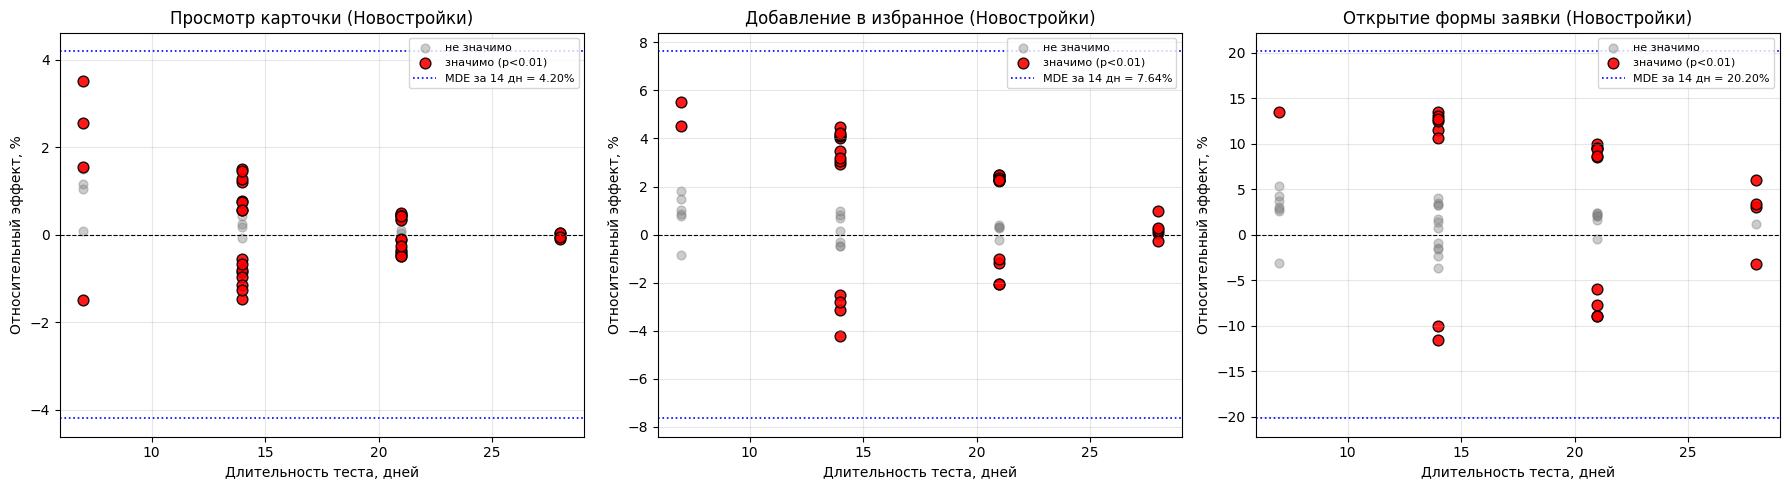

In [40]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ('card', 'Просмотр карточки (Новостройки)', p0_card, mde(p0_card, n_per_group)),
    ('fav',  'Добавление в избранное (Новостройки)', p0_fav, mde(p0_fav, n_per_group)),
    ('form', 'Открытие формы заявки (Новостройки)', p0_form, mde(p0_form, n_per_group)),
]

for ax, (key, title, p0_val, mde_val) in zip(axes, metrics):
    effect_col = f'proxy_{key}_effect_rel'
    pval_col   = f'proxy_{key}_p_value'

    sub = df_exps.dropna(subset=[effect_col, pval_col, 'days']).copy()
    sub['significant'] = sub[pval_col] < alpha

    sig   = sub[sub['significant']]
    insig = sub[~sub['significant']]

    ax.scatter(insig['days'], insig[effect_col] * 100,
               alpha=0.4, color='gray', label='не значимо', s=40)
    ax.scatter(sig['days'], sig[effect_col] * 100,
               alpha=0.9, color='red', label='значимо (p<0.01)', s=60, edgecolor='black')

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

    if mde_val is not None:
        ax.axhline(mde_val * 100, color='blue', linewidth=1.2, linestyle=':',
                   label=f'MDE за 14 дн = {mde_val*100:.2f}%')
        ax.axhline(-mde_val * 100, color='blue', linewidth=1.2, linestyle=':')

    ax.set_xlabel('Длительность теста, дней')
    ax.set_ylabel('Относительный эффект, %')
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 5. Выбираем proxy-метрику (шаг 2) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов рассчитайте:
- Binary Sensitivity;
- MSE с таргет-метрикой;
- Корреляцию Пирсона с таргет-метрикой.

In [46]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

alpha = 0.01

proxy_keys = ['card', 'fav', 'form']
proxy_titles = {
    'card': 'Просмотр карточки',
    'fav':  'Добавление в избранное',
    'form': 'Открытие формы заявки',
}


target_effect_col = 'target_contact_effect_rel'
target_pval_col   = 'target_contact_p_value'

results = []

for key in proxy_keys:
    eff_col  = f'proxy_{key}_effect_rel'
    pval_col = f'proxy_{key}_p_value'

    sub = df_exps.dropna(subset=[target_effect_col, target_pval_col,
                                 eff_col, pval_col]).copy()

    n = len(sub)

    target_sig = sub[target_pval_col] < alpha
    proxy_sig  = sub[pval_col] < alpha

    TP = int(( target_sig &  proxy_sig).sum())
    FN = int(( target_sig & ~proxy_sig).sum())
    FP = int((~target_sig &  proxy_sig).sum())
    TN = int((~target_sig & ~proxy_sig).sum())

    sensitivity = TP / (TP + FN) if (TP + FN) > 0 else np.nan
    specificity = TN / (TN + FP) if (TN + FP) > 0 else np.nan
    accuracy    = (TP + TN) / n

    mse = np.mean((sub[eff_col] - sub[target_effect_col])**2)
    r, p_r = pearsonr(sub[eff_col], sub[target_effect_col])

    results.append({
        'proxy': proxy_titles[key],
        'n': n,
        'TP': TP, 'FN': FN, 'FP': FP, 'TN': TN,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'Accuracy': accuracy,
        'MSE': mse,
        'Pearson r': r,
        'p-value r': p_r,
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                 proxy  n  TP  FN  FP  TN  Sensitivity  Specificity  Accuracy      MSE  Pearson r    p-value r
     Просмотр карточки 50  18   2  22   8         0.90     0.266667      0.52 0.014300   0.150005 2.984502e-01
Добавление в избранное 50  17   3  15  15         0.85     0.500000      0.64 0.011042   0.669678 1.048978e-07
 Открытие формы заявки 50  12   8  11  19         0.60     0.633333      0.62 0.006551   0.723834 2.856400e-09


IndentationError: unexpected indent (905277060.py, line 3)

#### 6. Выбираем proxy-метрику (шаг 3) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов:
- Рассчитайте Proxy Score;
- Выведите матрицу согласия-несогласия знаков с таргет-метрикой.

Выберите proxy, с которой вы пойдете в а/б тест, обоснуйте выбор.

In [51]:
alpha = 0.01

proxy_keys = ['card', 'fav', 'form']
proxy_titles = {
    'card': 'Просмотр карточки',
    'fav':  'Добавление в избранное',
    'form': 'Открытие формы заявки',
}

target_effect_col = 'target_contact_effect_rel'
target_pval_col   = 'target_contact_p_value'

results = []

for key in proxy_keys:
    eff_col  = f'proxy_{key}_effect_rel'
    pval_col = f'proxy_{key}_p_value'

    sub = df_exps.dropna(subset=[target_effect_col, target_pval_col,
                                 eff_col, pval_col]).copy()
    n = len(sub)
    if n < 3:
        print(f"{proxy_titles[key]}: недостаточно данных (n={n})")
        continue

    target_sig = sub[target_pval_col] < alpha
    proxy_sig  = sub[pval_col] < alpha
    TP = int(( target_sig &  proxy_sig).sum())
    FN = int(( target_sig & ~proxy_sig).sum())
    FP = int((~target_sig &  proxy_sig).sum())
    TN = int((~target_sig & ~proxy_sig).sum())
    sensitivity = TP / (TP + FN) if (TP + FN) > 0 else np.nan

    mse = np.mean((sub[eff_col] - sub[target_effect_col])**2)

    r, p_r = pearsonr(sub[eff_col], sub[target_effect_col])

    if not np.isnan(sensitivity):
        proxy_score = sensitivity * abs(r) / (1 + mse)
    else:
        proxy_score = np.nan

    sign_sub = sub[sub[target_effect_col] != 0].copy()
    sign_sub['target_sign'] = np.sign(sign_sub[target_effect_col])
    sign_sub['proxy_sign']  = np.sign(sign_sub[eff_col])

    agree_pp = int(((sign_sub['target_sign'] ==  1) & (sign_sub['proxy_sign'] ==  1)).sum())
    disagree_pn = int(((sign_sub['target_sign'] ==  1) & (sign_sub['proxy_sign'] == -1)).sum())
    disagree_np = int(((sign_sub['target_sign'] == -1) & (sign_sub['proxy_sign'] ==  1)).sum())
    agree_nn = int(((sign_sub['target_sign'] == -1) & (sign_sub['proxy_sign'] == -1)).sum())

    total_sign = agree_pp + disagree_pn + disagree_np + agree_nn
    agreement = (agree_pp + agree_nn) / total_sign if total_sign > 0 else np.nan

    results.append({
        'proxy': proxy_titles[key],
        'n': n,
        'Sensitivity': sensitivity,
        'MSE': mse,
        'Pearson r': r,
        'p-value r': p_r,
        'Proxy Score': proxy_score,
        'Согл. +/+': agree_pp,
        'Несогл. +/-': disagree_pn,
        'Несогл. -/+': disagree_np,
        'Согл. -/-': agree_nn,
        '% согласия знаков': agreement,
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                 proxy  n  Sensitivity      MSE  Pearson r    p-value r  Proxy Score  Согл. +/+  Несогл. +/-  Несогл. -/+  Согл. -/-  % согласия знаков
     Просмотр карточки 50         0.90 0.014300   0.150005 2.984502e-01     0.133101         28            8            1         13               0.82
Добавление в избранное 50         0.85 0.011042   0.669678 1.048978e-07     0.563009         36            0            0         14               1.00
 Открытие формы заявки 50         0.60 0.006551   0.723834 2.856400e-09     0.431474         36            0            0         14               1.00


In [50]:
for key in proxy_keys:
    eff_col  = f'proxy_{key}_effect_rel'
    pval_col = f'proxy_{key}_p_value'
    sub = df_exps.dropna(subset=[target_effect_col, eff_col]).copy()
    sub = sub[sub[target_effect_col] != 0]
    sub['target_sign'] = np.sign(sub[target_effect_col])
    sub['proxy_sign']  = np.sign(sub[eff_col])

    mat = pd.crosstab(sub['target_sign'], sub['proxy_sign'],
                      rownames=['target'], colnames=['proxy'])

    mat = mat.reindex(index=[-1, 1], columns=[-1, 1], fill_value=0)
    print(f"{proxy_titles[key]}:")
    print(mat)
    agree = mat.loc[1,1] + mat.loc[-1,-1]
    total = mat.values.sum()
    print(f"Согласие знаков: {agree}/{total} = {agree/total*100:.1f}%")

Просмотр карточки:
proxy   -1   1
target        
-1      13   1
 1       8  28
Согласие знаков: 41/50 = 82.0%
Добавление в избранное:
proxy   -1   1
target        
-1      14   0
 1       0  36
Согласие знаков: 50/50 = 100.0%
Открытие формы заявки:
proxy   -1   1
target        
-1      14   0
 1       0  36
Согласие знаков: 50/50 = 100.0%


По результатам анализа исторических экспериментов (n = 50) лучше выбрать proxy-метрика add_fav (добавление в избранное в Новостройках).

У нее наивысший Proxy Score = 0.563

100% согласие знаков эффекта с таргетом (50/50), тогда как у card_view — 82% (9 несогласий, включая 8 случаев ложного отрицательного сигнала)

Приемлемая Sensitivity

Сильная значимая корреляция с таргетом по Пирсону


card_view отклонена из-за отсутствия значимой корреляции с таргетом (r = 0.15, p = 0.30) и большого числа несогласий по знаку, несмотря на высокую Sensitivity

form_start отклонена из-за низкой Sensitivity (0.60) и недостижимого MDE за 14 дней (низкая p0)